In [1]:
%pip install minisom scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install rosbags numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install open3d

Note: you may need to restart the kernel to use updated packages.


# Which data set do you want to use?  Comment out the appropriate set, make sure you put the correct path in for your end point

In [12]:
import sqlite3
import pandas as pd

# Change this to the path of your .db3 file
#db3_path = r"C:\Users\miken\OneDrive\Desktop\lab2\ai_labs\data\kitti_2011_09_26_drive_0005_jazzy\kitti_2011_09_26_drive_0005_jazzy.db3"
db3_path = r"C:\Users\miken\OneDrive\Desktop\lab2\ai_labs\data\kitti_2011_09_26_drive_0002_jazzy\kitti_2011_09_26_drive_0002_jazzy.db3"

conn = sqlite3.connect(db3_path)

topics = pd.read_sql_query("""
    SELECT
        id,
        name,
        type,
        serialization_format
    FROM topics
""", conn)

display(topics)

conn.close()

,id,name,type,serialization_format
0,1,/tf_static,tf2_msgs/msg/TFMessage,cdr
1,2,/tf,tf2_msgs/msg/TFMessage,cdr
2,3,/kitti/oxts/imu,sensor_msgs/msg/Imu,cdr
3,4,/kitti/oxts/gps/fix,sensor_msgs/msg/NavSatFix,cdr
4,5,/kitti/oxts/gps/vel,geometry_msgs/msg/TwistStamped,cdr
5,6,/kitti/camera_gray_left/image_raw,sensor_msgs/msg/Image,cdr
6,7,/kitti/camera_gray_left/camera_info,sensor_msgs/msg/CameraInfo,cdr
7,8,/kitti/camera_gray_right/image_raw,sensor_msgs/msg/Image,cdr
8,9,/kitti/camera_gray_right/camera_info,sensor_msgs/msg/CameraInfo,cdr
9,10,/kitti/camera_color_left/image_raw,sensor_msgs/msg/Image,cdr


In [13]:
conn = sqlite3.connect(db3_path)

counts = pd.read_sql_query("""
    SELECT
        topics.name,
        topics.type,
        COUNT(messages.id) AS message_count
    FROM topics
    LEFT JOIN messages
        ON topics.id = messages.topic_id
    GROUP BY topics.id
    ORDER BY topics.id
""", conn)

display(counts)

conn.close()

,name,type,message_count
0,/tf_static,tf2_msgs/msg/TFMessage,77
1,/tf,tf2_msgs/msg/TFMessage,77
2,/kitti/oxts/imu,sensor_msgs/msg/Imu,77
3,/kitti/oxts/gps/fix,sensor_msgs/msg/NavSatFix,77
4,/kitti/oxts/gps/vel,geometry_msgs/msg/TwistStamped,77
5,/kitti/camera_gray_left/image_raw,sensor_msgs/msg/Image,77
6,/kitti/camera_gray_left/camera_info,sensor_msgs/msg/CameraInfo,77
7,/kitti/camera_gray_right/image_raw,sensor_msgs/msg/Image,77
8,/kitti/camera_gray_right/camera_info,sensor_msgs/msg/CameraInfo,77
9,/kitti/camera_color_left/image_raw,sensor_msgs/msg/Image,77


# open up the desired camera, left or right. Type in the frame you want to observe, 0-76 or 0-153 depending on the data set.

Frame: 50
Image width: 1242
Image height: 375
Encoding: bgr8


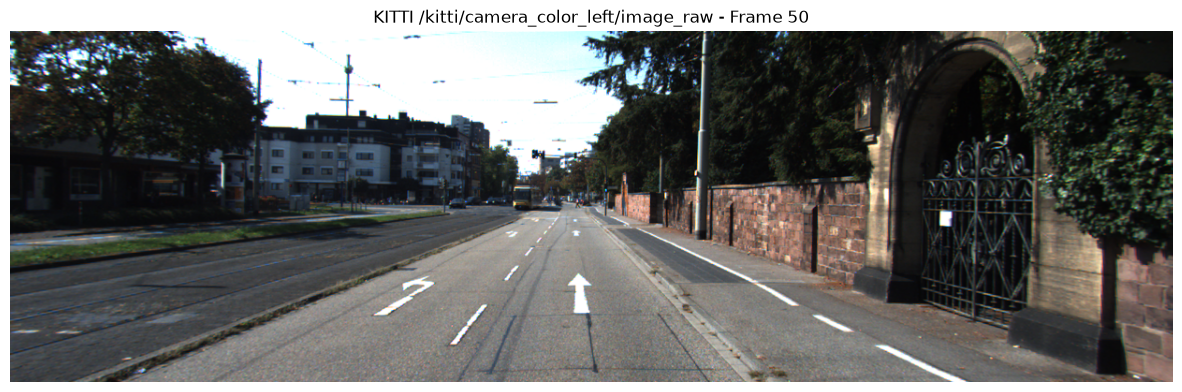

In [17]:
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
from rosbags.typesys import get_typestore, Stores

# ==========================================
# USER SETTINGS
# ==========================================

frame_number = 50  # Select frame 0 through 153

camera_topic = "/kitti/camera_color_left/image_raw"

# Other available cameras:
# "/kitti/camera_color_right/image_raw"
# "/kitti/camera_gray_left/image_raw"
# "/kitti/camera_gray_right/image_raw"

# ==========================================
# READ CAMERA FRAME FROM ROS2 BAG
# ==========================================

typestore = get_typestore(Stores.ROS2_HUMBLE)

conn = sqlite3.connect(db3_path)
cursor = conn.cursor()

cursor.execute("""
    SELECT messages.data
    FROM messages
    JOIN topics ON messages.topic_id = topics.id
    WHERE topics.name = ?
    ORDER BY messages.timestamp
    LIMIT 1 OFFSET ?
""", (camera_topic, frame_number))

row = cursor.fetchone()
conn.close()

if row is None:
    raise ValueError(f"Frame {frame_number} not found")

# Deserialize ROS2 Image message
msg = typestore.deserialize_cdr(
    row[0],
    "sensor_msgs/msg/Image"
)

print("Frame:", frame_number)
print("Image width:", msg.width)
print("Image height:", msg.height)
print("Encoding:", msg.encoding)

# ==========================================
# CONVERT IMAGE TO NUMPY ARRAY
# ==========================================

encoding = msg.encoding.lower()

channels = {
    "rgb8": 3,
    "bgr8": 3,
    "rgba8": 4,
    "bgra8": 4,
    "mono8": 1,
}

if encoding not in channels:
    raise ValueError(f"Unsupported encoding: {msg.encoding}")

num_channels = channels[encoding]
row_width = msg.width * num_channels

raw = np.frombuffer(msg.data, dtype=np.uint8)
image = raw.reshape(msg.height, msg.step)[:, :row_width]

if num_channels == 1:
    image = image.reshape(msg.height, msg.width)
else:
    image = image.reshape(msg.height, msg.width, num_channels)

if encoding == "bgr8":
    image = image[:, :, ::-1]
elif encoding == "bgra8":
    image = image[:, :, [2, 1, 0, 3]]

# ==========================================
# DISPLAY IMAGE
# ==========================================

plt.figure(figsize=(15, 7))
plt.imshow(image, cmap="gray" if num_channels == 1 else None)
plt.axis("off")
plt.title(f"KITTI {camera_topic} - Frame {frame_number}")
plt.show()